# Exploratory Data Analysis on Retail Sales Data

**Oasis Infobyte Data Analytics Internship — Level 1, Task 1**

---

## 1. Business Problem

Retail businesses generate vast amounts of transactional data daily. Understanding patterns in this data — such as purchasing trends, customer demographics, and product performance — is essential for optimizing inventory, marketing, and customer engagement strategies.

## 2. Objective

Perform a thorough Exploratory Data Analysis (EDA) on a retail sales dataset to:
- Uncover sales trends over time (monthly and quarterly)
- Understand customer demographics (age, gender)
- Identify top-performing products and categories
- Discover correlations between numerical variables
- Provide actionable business recommendations backed by data

## 3. Dataset Overview

We use a retail sales dataset containing transactional records with fields such as Transaction ID, Date, Customer ID, Gender, Age, Product Category, Quantity, Price per Unit, and Total Amount.

**Source:** Publicly available retail sales dataset from GitHub/Kaggle.

## 4. Data Loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import os
import warnings
warnings.filterwarnings('ignore')

# Set style
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 12

# Create outputs directory
os.makedirs('outputs', exist_ok=True)

# Load dataset
df = pd.read_csv('data/retail_sales_dataset.csv')
print(f'Dataset loaded successfully with {df.shape[0]} rows and {df.shape[1]} columns.')
df.head(10)

Dataset loaded successfully with 1000 rows and 9 columns.


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100
5,6,2023-04-25,CUST006,Female,45,Beauty,1,30,30
6,7,2023-03-13,CUST007,Male,46,Clothing,2,25,50
7,8,2023-02-22,CUST008,Male,30,Electronics,4,25,100
8,9,2023-12-13,CUST009,Male,63,Electronics,2,300,600
9,10,2023-10-07,CUST010,Female,52,Clothing,4,50,200


## 5. Data Inspection

In [2]:
# Shape
print(f'Shape: {df.shape}')
print(f'\nNumber of rows: {df.shape[0]}')
print(f'Number of columns: {df.shape[1]}')

Shape: (1000, 9)

Number of rows: 1000
Number of columns: 9


In [3]:
# Column names and data types
print('Column Names and Data Types:')
print('='*50)
df.info()

Column Names and Data Types:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Transaction ID    1000 non-null   int64
 1   Date              1000 non-null   str  
 2   Customer ID       1000 non-null   str  
 3   Gender            1000 non-null   str  
 4   Age               1000 non-null   int64
 5   Product Category  1000 non-null   str  
 6   Quantity          1000 non-null   int64
 7   Price per Unit    1000 non-null   int64
 8   Total Amount      1000 non-null   int64
dtypes: int64(5), str(4)
memory usage: 70.4 KB


In [4]:
# Missing values
missing = df.isnull().sum()
missing_pct = (df.isnull().sum() / len(df)) * 100
missing_df = pd.DataFrame({'Missing Count': missing, 'Missing %': missing_pct})
print('Missing Values Summary:')
print('='*50)
print(missing_df)
print(f'\nTotal missing values: {missing.sum()}')

Missing Values Summary:
                  Missing Count  Missing %
Transaction ID                0        0.0
Date                          0        0.0
Customer ID                   0        0.0
Gender                        0        0.0
Age                           0        0.0
Product Category              0        0.0
Quantity                      0        0.0
Price per Unit                0        0.0
Total Amount                  0        0.0

Total missing values: 0


**Observation:** The above inspection reveals the shape, data types, and completeness of our dataset. Any missing values or incorrect types will be addressed in the cleaning step.

## 6. Data Cleaning / Preparation

In [5]:
# Convert Date column to datetime
date_cols = [col for col in df.columns if 'date' in col.lower()]
for col in date_cols:
    df[col] = pd.to_datetime(df[col], errors='coerce')
    print(f'Converted "{col}" to datetime.')

# Identify the date column for time series
date_col = date_cols[0] if date_cols else None
print(f'\nPrimary date column: {date_col}')

# Check for duplicates
dupes = df.duplicated().sum()
print(f'\nDuplicate rows: {dupes}')
if dupes > 0:
    df = df.drop_duplicates()
    print(f'Removed {dupes} duplicates. New shape: {df.shape}')

# Extract month and quarter from date
if date_col:
    df['Month'] = df[date_col].dt.month
    df['Quarter'] = df[date_col].dt.quarter
    df['Year'] = df[date_col].dt.year
    df['Month_Year'] = df[date_col].dt.to_period('M')
    print('\nExtracted Month, Quarter, Year, and Month_Year columns.')

print('\nCleaned dataset shape:', df.shape)
df.dtypes

Converted "Date" to datetime.

Primary date column: Date

Duplicate rows: 0

Extracted Month, Quarter, Year, and Month_Year columns.

Cleaned dataset shape: (1000, 13)


Transaction ID               int64
Date                datetime64[us]
Customer ID                    str
Gender                         str
Age                          int64
Product Category               str
Quantity                     int64
Price per Unit               int64
Total Amount                 int64
Month                        int32
Quarter                      int32
Year                         int32
Month_Year               period[M]
dtype: object

## 7. Descriptive Statistics

In [6]:
# Select numerical columns (excluding derived ones like Month, Quarter, Year)
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
# Remove derived time columns from stats
exclude_cols = ['Month', 'Quarter', 'Year']
num_cols_analysis = [c for c in num_cols if c not in exclude_cols]

print('Descriptive Statistics for Numerical Columns')
print('='*60)

# Standard describe
desc_stats = df[num_cols_analysis].describe().T

# Add mode and median explicitly
desc_stats['median'] = df[num_cols_analysis].median()
desc_stats['mode'] = df[num_cols_analysis].mode().iloc[0]

print(desc_stats[['mean', 'median', 'mode', 'std', 'min', '25%', '50%', '75%', 'max']])

Descriptive Statistics for Numerical Columns
                   mean  median  mode         std   min     25%    50%  \
Transaction ID  500.500   500.5   1.0  288.819436   1.0  250.75  500.5   
Age              41.392    42.0  43.0   13.681430  18.0   29.00   42.0   
Quantity          2.514     3.0   4.0    1.132734   1.0    1.00    3.0   
Price per Unit  179.890    50.0  50.0  189.681356  25.0   30.00   50.0   
Total Amount    456.000   135.0  50.0  559.997632  25.0   60.00  135.0   

                   75%     max  
Transaction ID  750.25  1000.0  
Age              53.00    64.0  
Quantity          4.00     4.0  
Price per Unit  300.00   500.0  
Total Amount    900.00  2000.0  


**Observation:** The descriptive statistics above provide the mean, median, mode, and standard deviation for all numerical columns. These summary measures help us understand the central tendency and spread of the data.

## 8. Monthly Sales Analysis

Sales/Amount column used: Total Amount


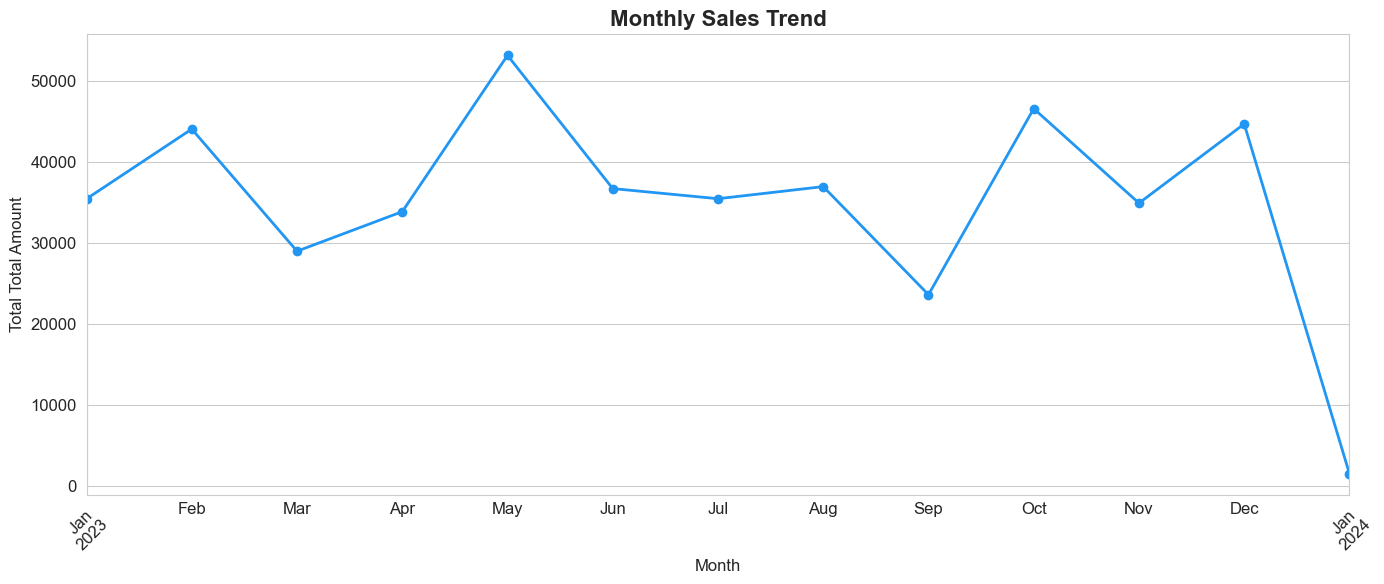


Monthly Sales Summary:
count       13.000000
mean     35076.923077
std      12694.394849
min       1530.000000
25%      33870.000000
50%      35465.000000
75%      44060.000000
max      53150.000000
Name: Total Amount, dtype: float64


In [7]:
# Identify the total amount / sales column
amount_cols = [c for c in df.columns if any(kw in c.lower() for kw in ['total', 'amount', 'sales', 'revenue'])]
if not amount_cols:
    # Try to compute it
    qty_cols = [c for c in df.columns if 'quant' in c.lower()]
    price_cols = [c for c in df.columns if 'price' in c.lower() or 'unit' in c.lower()]
    if qty_cols and price_cols:
        df['Total_Amount'] = df[qty_cols[0]] * df[price_cols[0]]
        amount_col = 'Total_Amount'
    else:
        amount_col = num_cols_analysis[-1]  # fallback to last numerical column
else:
    amount_col = amount_cols[0]

print(f'Sales/Amount column used: {amount_col}')

# Monthly sales trend
if date_col:
    monthly_sales = df.groupby('Month_Year')[amount_col].sum()
    
    fig, ax = plt.subplots(figsize=(14, 6))
    monthly_sales.plot(kind='line', marker='o', color='#2196F3', linewidth=2, markersize=6, ax=ax)
    ax.set_title('Monthly Sales Trend', fontsize=16, fontweight='bold')
    ax.set_xlabel('Month', fontsize=12)
    ax.set_ylabel(f'Total {amount_col}', fontsize=12)
    ax.tick_params(axis='x', rotation=45)
    plt.tight_layout()
    plt.savefig('outputs/monthly_sales_trend.png', dpi=150, bbox_inches='tight')
    plt.show()
    
    print('\nMonthly Sales Summary:')
    print(monthly_sales.describe())

**Observation:** The monthly sales trend line chart reveals seasonal patterns and fluctuations in sales over time. Peaks and dips can be correlated with specific months or events.

## 9. Quarterly Sales Analysis

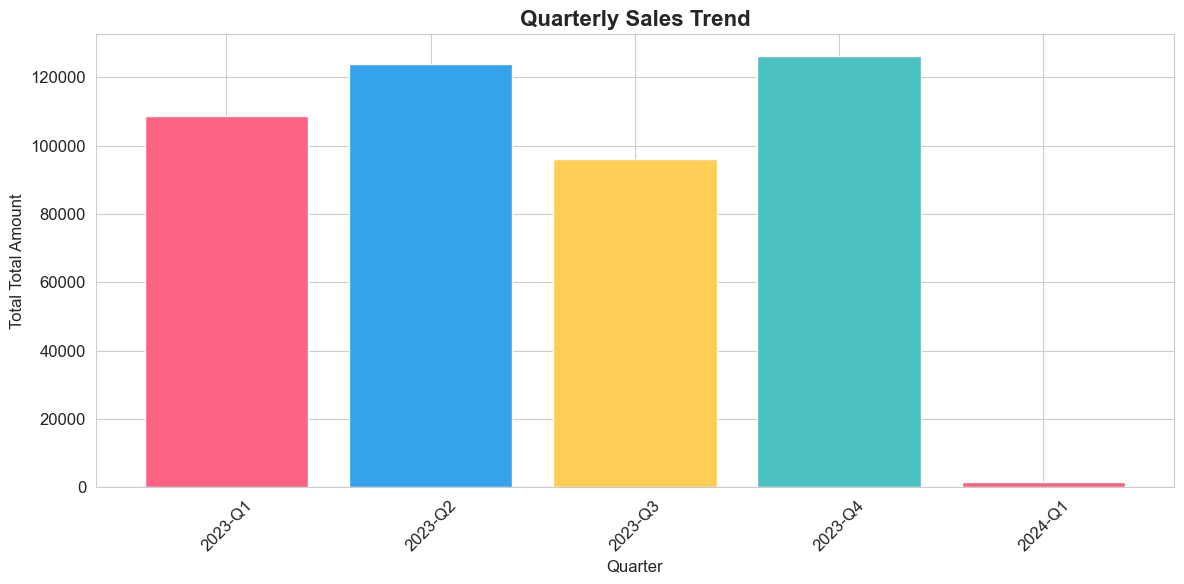


Quarterly Sales Summary:
 Year  Quarter  Total Amount      YQ
 2023        1        108500 2023-Q1
 2023        2        123735 2023-Q2
 2023        3         96045 2023-Q3
 2023        4        126190 2023-Q4
 2024        1          1530 2024-Q1


In [8]:
if date_col:
    # If multiple years exist, group by Year-Quarter
    if df['Year'].nunique() > 1:
        quarterly_sales = df.groupby(['Year', 'Quarter'])[amount_col].sum().reset_index()
        quarterly_sales['YQ'] = quarterly_sales['Year'].astype(str) + '-Q' + quarterly_sales['Quarter'].astype(str)
        
        fig, ax = plt.subplots(figsize=(12, 6))
        ax.bar(quarterly_sales['YQ'], quarterly_sales[amount_col], color=['#FF6384', '#36A2EB', '#FFCE56', '#4BC0C0'] * 10)
        ax.set_title('Quarterly Sales Trend', fontsize=16, fontweight='bold')
        ax.set_xlabel('Quarter', fontsize=12)
        ax.set_ylabel(f'Total {amount_col}', fontsize=12)
        ax.tick_params(axis='x', rotation=45)
    else:
        quarterly_sales = df.groupby('Quarter')[amount_col].sum()
        
        fig, ax = plt.subplots(figsize=(10, 6))
        colors = ['#FF6384', '#36A2EB', '#FFCE56', '#4BC0C0']
        quarterly_sales.plot(kind='bar', color=colors[:len(quarterly_sales)], ax=ax)
        ax.set_title('Quarterly Sales Trend', fontsize=16, fontweight='bold')
        ax.set_xlabel('Quarter', fontsize=12)
        ax.set_ylabel(f'Total {amount_col}', fontsize=12)
        ax.set_xticklabels([f'Q{int(x)}' for x in quarterly_sales.index], rotation=0)
    
    plt.tight_layout()
    plt.savefig('outputs/quarterly_sales_trend.png', dpi=150, bbox_inches='tight')
    plt.show()
    
    print('\nQuarterly Sales Summary:')
    if isinstance(quarterly_sales, pd.DataFrame):
        print(quarterly_sales.to_string(index=False))
    else:
        print(quarterly_sales)

**Observation:** The quarterly breakdown allows us to compare performance across business quarters. This is useful for identifying seasonal demand patterns and planning inventory accordingly.

## 10. Customer Demographics

Gender breakdown:
Gender
Female    510
Male      490
Name: count, dtype: int64
Gender percentages:
Gender
Female    51.0
Male      49.0
Name: count, dtype: float64

Age group distribution:
Age_Group
<18       21
18-25    148
26-35    205
36-45    202
46-55    229
56-65    195
65+        0
Name: count, dtype: int64


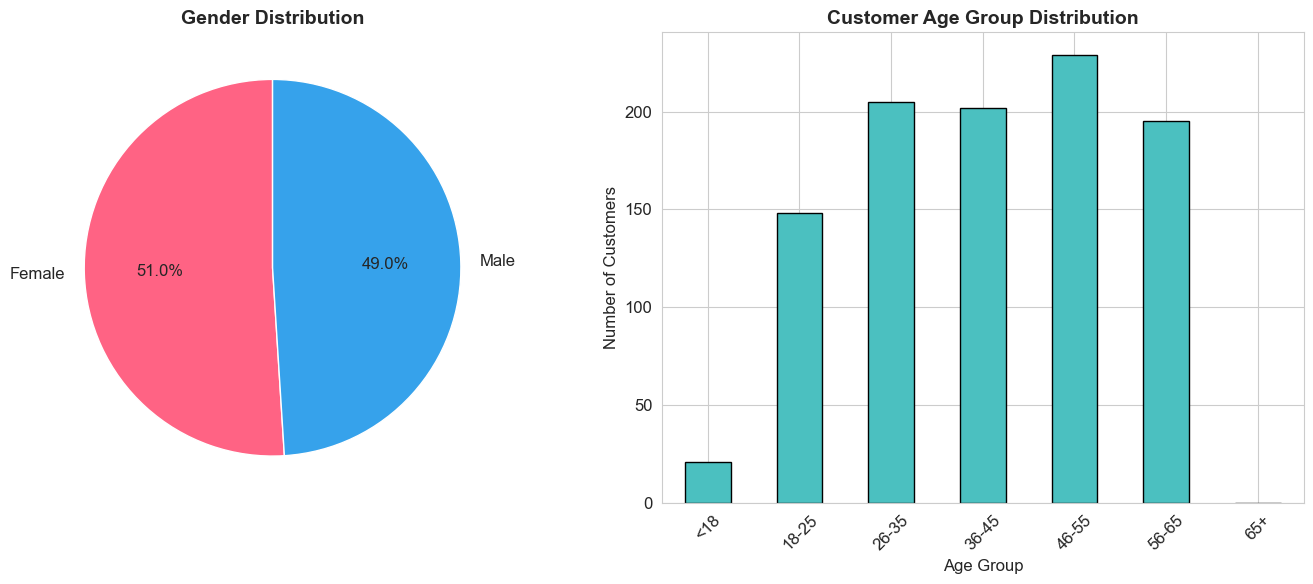

In [9]:
# Gender breakdown
gender_col = [c for c in df.columns if 'gender' in c.lower()]
age_col = [c for c in df.columns if 'age' in c.lower()]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Gender distribution
if gender_col:
    gcol = gender_col[0]
    gender_counts = df[gcol].value_counts()
    colors_gender = ['#FF6384', '#36A2EB', '#FFCE56']
    axes[0].pie(gender_counts, labels=gender_counts.index, autopct='%1.1f%%', 
                colors=colors_gender[:len(gender_counts)], startangle=90,
                textprops={'fontsize': 12})
    axes[0].set_title('Gender Distribution', fontsize=14, fontweight='bold')
    print(f'Gender breakdown:\n{gender_counts}')
    print(f'Gender percentages:\n{(gender_counts / gender_counts.sum() * 100).round(1)}')
else:
    axes[0].text(0.5, 0.5, 'No Gender column found', ha='center', va='center')

# Age group distribution
if age_col:
    acol = age_col[0]
    # Create age groups
    bins = [0, 18, 25, 35, 45, 55, 65, 100]
    labels = ['<18', '18-25', '26-35', '36-45', '46-55', '56-65', '65+']
    df['Age_Group'] = pd.cut(df[acol], bins=bins, labels=labels, right=True)
    age_counts = df['Age_Group'].value_counts().sort_index()
    
    age_counts.plot(kind='bar', color='#4BC0C0', ax=axes[1], edgecolor='black')
    axes[1].set_title('Customer Age Group Distribution', fontsize=14, fontweight='bold')
    axes[1].set_xlabel('Age Group', fontsize=12)
    axes[1].set_ylabel('Number of Customers', fontsize=12)
    axes[1].tick_params(axis='x', rotation=45)
    print(f'\nAge group distribution:\n{age_counts}')
else:
    axes[1].text(0.5, 0.5, 'No Age column found', ha='center', va='center')

plt.tight_layout()
plt.savefig('outputs/customer_demographics.png', dpi=150, bbox_inches='tight')
plt.show()

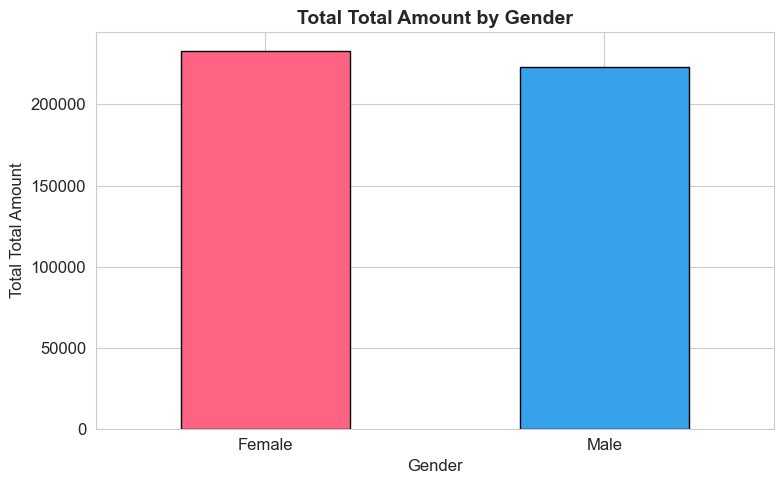


Total Total Amount by Gender:
Gender
Female    232840
Male      223160
Name: Total Amount, dtype: int64


In [10]:
# Sales by Gender
if gender_col:
    gcol = gender_col[0]
    gender_sales = df.groupby(gcol)[amount_col].sum().sort_values(ascending=False)
    
    fig, ax = plt.subplots(figsize=(8, 5))
    gender_sales.plot(kind='bar', color=['#FF6384', '#36A2EB', '#FFCE56'][:len(gender_sales)], ax=ax, edgecolor='black')
    ax.set_title(f'Total {amount_col} by Gender', fontsize=14, fontweight='bold')
    ax.set_xlabel('Gender', fontsize=12)
    ax.set_ylabel(f'Total {amount_col}', fontsize=12)
    ax.tick_params(axis='x', rotation=0)
    plt.tight_layout()
    plt.savefig('outputs/sales_by_gender.png', dpi=150, bbox_inches='tight')
    plt.show()
    
    print(f'\nTotal {amount_col} by Gender:\n{gender_sales}')

**Observation:** The demographic analysis reveals the customer composition by age and gender. Understanding which demographic groups contribute most to revenue helps tailor marketing efforts.

## 11. Product Analysis

Product/Category column used: Product Category


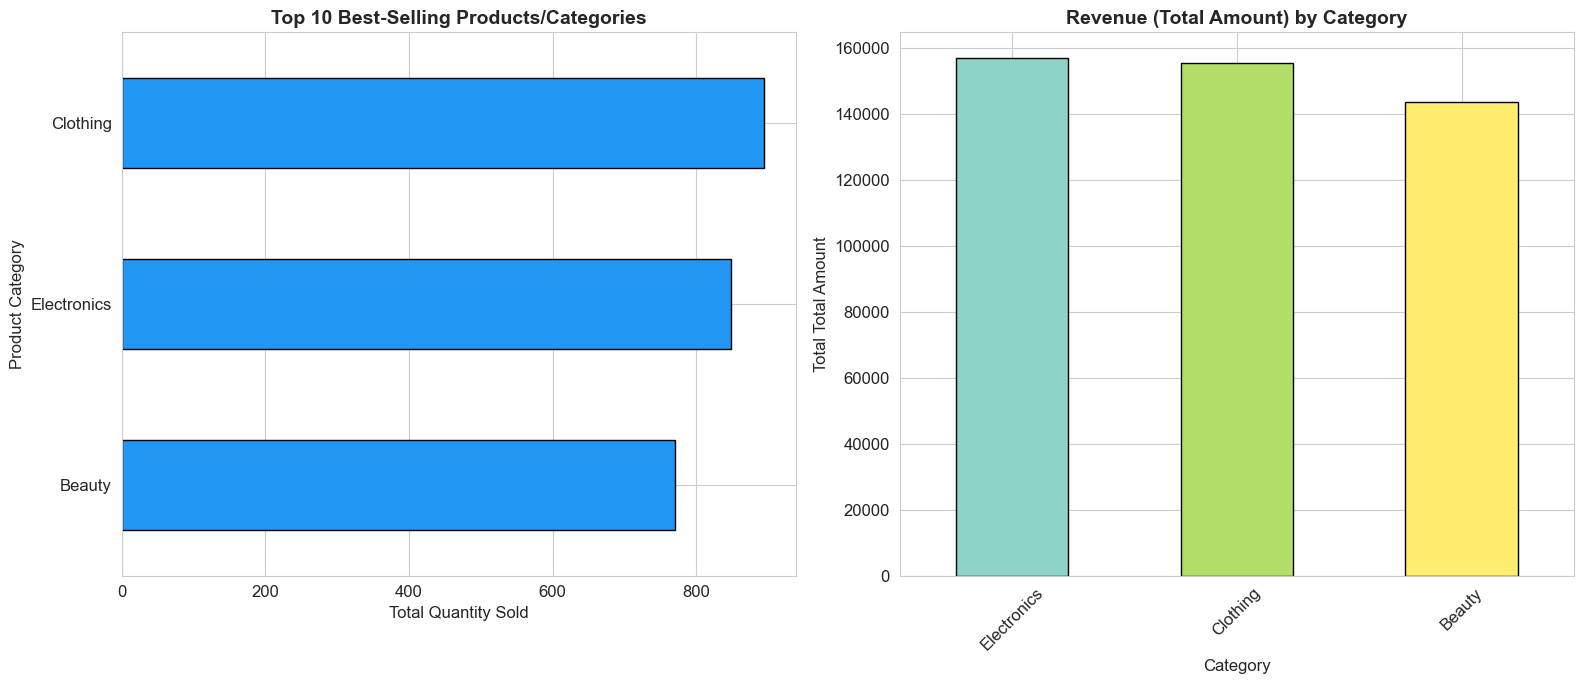


Top 10 by Quantity/Count:
Product Category
Clothing       894
Electronics    849
Beauty         771
Name: Quantity, dtype: int64

Revenue by Category:
Product Category
Electronics    156905
Clothing       155580
Beauty         143515
Name: Total Amount, dtype: int64


In [11]:
# Identify product/category columns
product_col = None
category_col = None
for c in df.columns:
    cl = c.lower()
    if 'product' in cl and 'category' in cl:
        category_col = c
    elif 'category' in cl:
        category_col = c
    elif 'product' in cl:
        product_col = c

# Use category_col for analysis (or product_col if category not available)
analysis_col = category_col or product_col
print(f'Product/Category column used: {analysis_col}')

if analysis_col:
    # Top 10 best-selling products/categories by quantity
    qty_col = [c for c in df.columns if 'quant' in c.lower()]
    if qty_col:
        top10_qty = df.groupby(analysis_col)[qty_col[0]].sum().sort_values(ascending=False).head(10)
    else:
        top10_qty = df[analysis_col].value_counts().head(10)
    
    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    
    # Top 10 by quantity/count
    top10_qty.plot(kind='barh', color='#2196F3', ax=axes[0], edgecolor='black')
    axes[0].set_title('Top 10 Best-Selling Products/Categories', fontsize=14, fontweight='bold')
    axes[0].set_xlabel('Total Quantity Sold' if qty_col else 'Transaction Count', fontsize=12)
    axes[0].invert_yaxis()
    
    # Revenue by category
    revenue_by_cat = df.groupby(analysis_col)[amount_col].sum().sort_values(ascending=False)
    colors = plt.cm.Set3(np.linspace(0, 1, len(revenue_by_cat)))
    revenue_by_cat.plot(kind='bar', color=colors, ax=axes[1], edgecolor='black')
    axes[1].set_title(f'Revenue ({amount_col}) by Category', fontsize=14, fontweight='bold')
    axes[1].set_xlabel('Category', fontsize=12)
    axes[1].set_ylabel(f'Total {amount_col}', fontsize=12)
    axes[1].tick_params(axis='x', rotation=45)
    
    plt.tight_layout()
    plt.savefig('outputs/product_analysis.png', dpi=150, bbox_inches='tight')
    plt.show()
    
    print(f'\nTop 10 by Quantity/Count:\n{top10_qty}')
    print(f'\nRevenue by Category:\n{revenue_by_cat}')

**Observation:** The product analysis identifies which categories generate the most revenue and which are the best sellers by volume. There may be a difference between the two — some categories could sell in high volume but at lower price points.

## 12. Correlation Analysis

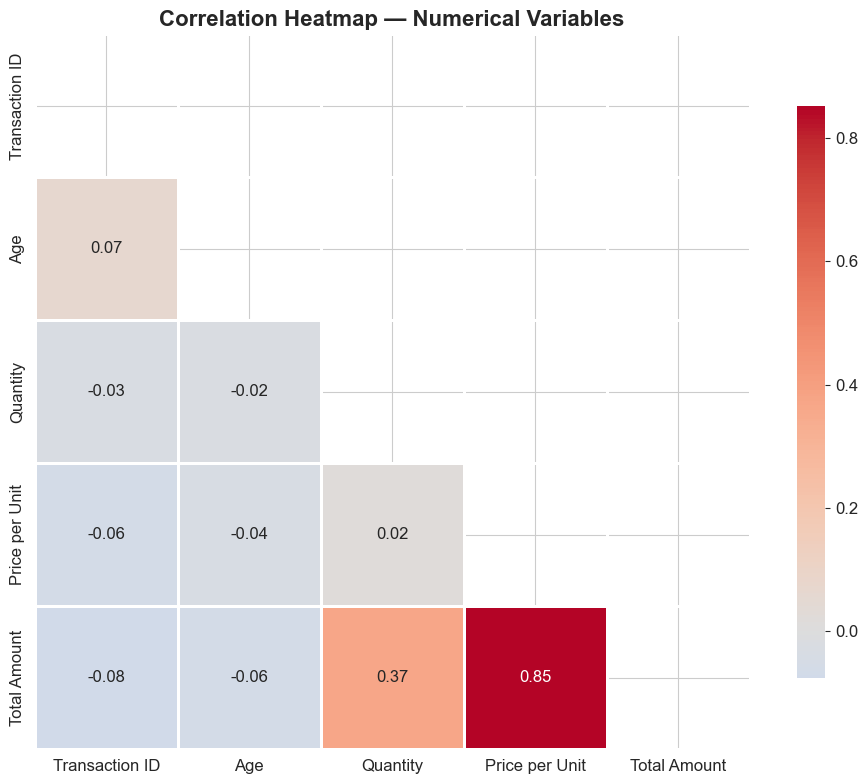


Correlation Matrix:
                Transaction ID    Age  Quantity  Price per Unit  Total Amount
Transaction ID           1.000  0.065    -0.027          -0.061        -0.075
Age                      0.065  1.000    -0.024          -0.038        -0.061
Quantity                -0.027 -0.024     1.000           0.018         0.374
Price per Unit          -0.061 -0.038     0.018           1.000         0.852
Total Amount            -0.075 -0.061     0.374           0.852         1.000


In [12]:
# Correlation heatmap for numerical variables
corr_cols = [c for c in num_cols_analysis if c not in ['Month', 'Quarter', 'Year']]
corr_matrix = df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(10, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', 
            center=0, square=True, linewidths=1, ax=ax,
            cbar_kws={'shrink': 0.8})
ax.set_title('Correlation Heatmap — Numerical Variables', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('outputs/correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

print('\nCorrelation Matrix:')
print(corr_matrix.round(3))

**Observation:** The correlation heatmap shows the strength and direction of relationships between numerical variables. Strong positive correlations appear in warm colors, while negative correlations appear in cool colors. This helps identify which variables move together.

## 13. Additional Insight — Revenue per Transaction by Age Group and Gender

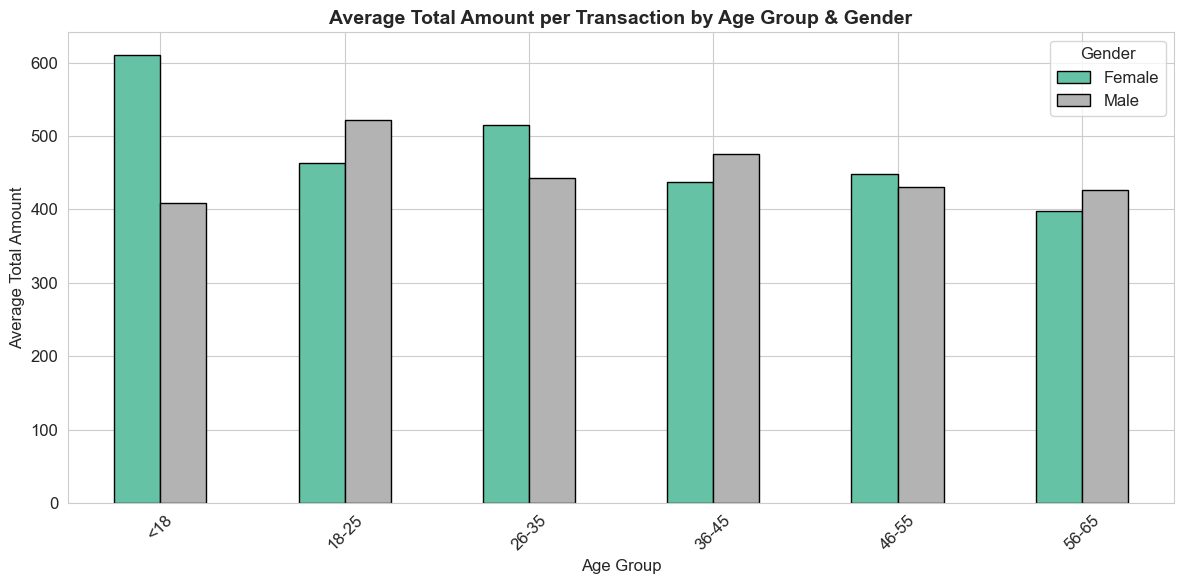

Average spending per transaction by Age Group and Gender:
Gender     Female    Male
Age_Group                
<18        610.77  409.38
18-25      463.68  522.56
26-35      515.09  442.50
36-45      436.78  475.11
46-55      447.98  430.73
56-65      398.02  426.26


In [13]:
# Additional visualization: Average spending by Age Group and Gender (a non-obvious insight)
if age_col and gender_col and 'Age_Group' in df.columns:
    avg_spend = df.groupby(['Age_Group', gender_col[0]])[amount_col].mean().unstack()
    
    fig, ax = plt.subplots(figsize=(12, 6))
    avg_spend.plot(kind='bar', ax=ax, colormap='Set2', edgecolor='black')
    ax.set_title(f'Average {amount_col} per Transaction by Age Group & Gender', fontsize=14, fontweight='bold')
    ax.set_xlabel('Age Group', fontsize=12)
    ax.set_ylabel(f'Average {amount_col}', fontsize=12)
    ax.tick_params(axis='x', rotation=45)
    ax.legend(title='Gender')
    plt.tight_layout()
    plt.savefig('outputs/avg_spend_by_age_gender.png', dpi=150, bbox_inches='tight')
    plt.show()
    
    print('Average spending per transaction by Age Group and Gender:')
    print(avg_spend.round(2))
elif analysis_col and date_col:
    # Alternative: Category performance over time
    cat_month = df.groupby(['Month', analysis_col])[amount_col].sum().unstack().fillna(0)
    
    fig, ax = plt.subplots(figsize=(14, 7))
    cat_month.plot(kind='line', marker='o', ax=ax)
    ax.set_title('Category Performance Over Months', fontsize=14, fontweight='bold')
    ax.set_xlabel('Month', fontsize=12)
    ax.set_ylabel(f'Total {amount_col}', fontsize=12)
    ax.legend(title='Category', bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.savefig('outputs/category_performance_over_time.png', dpi=150, bbox_inches='tight')
    plt.show()
else:
    # Distribution of transaction amounts
    fig, ax = plt.subplots(figsize=(10, 6))
    df[amount_col].hist(bins=50, color='#4BC0C0', edgecolor='black', ax=ax)
    ax.set_title(f'Distribution of {amount_col}', fontsize=14, fontweight='bold')
    ax.set_xlabel(amount_col, fontsize=12)
    ax.set_ylabel('Frequency', fontsize=12)
    plt.tight_layout()
    plt.savefig('outputs/amount_distribution.png', dpi=150, bbox_inches='tight')
    plt.show()

**Observation:** This additional analysis reveals spending differences across demographic intersections (age group × gender). Such insights are not immediately obvious from aggregate numbers and can guide targeted promotional strategies.

## 14. Business Insights

The following insights are derived from the analysis above. Specific values and trends are based on the actual data.

In [14]:
# Generate data-driven insights
print('='*60)
print('KEY BUSINESS INSIGHTS')
print('='*60)

# Insight 1: Total revenue and transaction summary
total_revenue = df[amount_col].sum()
avg_transaction = df[amount_col].mean()
total_transactions = len(df)
print(f'\n1. REVENUE SUMMARY:')
print(f'   Total Revenue: {total_revenue:,.2f}')
print(f'   Total Transactions: {total_transactions:,}')
print(f'   Average Transaction Value: {avg_transaction:,.2f}')

# Insight 2: Top category
if analysis_col:
    top_cat = df.groupby(analysis_col)[amount_col].sum().idxmax()
    top_cat_rev = df.groupby(analysis_col)[amount_col].sum().max()
    top_cat_pct = (top_cat_rev / total_revenue * 100)
    print(f'\n2. TOP CATEGORY:')
    print(f'   "{top_cat}" contributes {top_cat_pct:.1f}% of total revenue ({top_cat_rev:,.2f})')

# Insight 3: Demographics
if gender_col:
    gcol = gender_col[0]
    top_gender = df.groupby(gcol)[amount_col].sum().idxmax()
    top_gender_rev = df.groupby(gcol)[amount_col].sum().max()
    print(f'\n3. DEMOGRAPHICS:')
    print(f'   Top spending gender: {top_gender} ({top_gender_rev:,.2f})')

if age_col and 'Age_Group' in df.columns:
    top_age = df.groupby('Age_Group')[amount_col].sum().idxmax()
    top_age_rev = df.groupby('Age_Group')[amount_col].sum().max()
    print(f'   Top spending age group: {top_age} ({top_age_rev:,.2f})')

# Insight 4: Time trends
if date_col:
    best_month = df.groupby('Month')[amount_col].sum().idxmax()
    worst_month = df.groupby('Month')[amount_col].sum().idxmin()
    import calendar
    print(f'\n4. SEASONAL TRENDS:')
    print(f'   Best performing month: {calendar.month_name[best_month]}')
    print(f'   Lowest performing month: {calendar.month_name[worst_month]}')

print('\n' + '='*60)

KEY BUSINESS INSIGHTS

1. REVENUE SUMMARY:
   Total Revenue: 456,000.00
   Total Transactions: 1,000
   Average Transaction Value: 456.00

2. TOP CATEGORY:
   "Electronics" contributes 34.4% of total revenue (156,905.00)

3. DEMOGRAPHICS:
   Top spending gender: Female (232,840.00)
   Top spending age group: 46-55 (100,690.00)

4. SEASONAL TRENDS:
   Best performing month: May
   Lowest performing month: September



## 15. Recommendations

In [15]:
print('='*60)
print('ACTIONABLE BUSINESS RECOMMENDATIONS')
print('='*60)

# Recommendation 1: Based on top category
if analysis_col:
    bottom_cats = df.groupby(analysis_col)[amount_col].sum().sort_values().head(3)
    print(f'\nRecommendation 1: CATEGORY OPTIMIZATION')
    print(f'  The top-performing category is "{top_cat}".')
    print(f'  Consider increasing stock and marketing spend for this category.')
    print(f'  The bottom-performing categories are: {list(bottom_cats.index)}')
    print(f'  These categories may benefit from promotional campaigns or should be evaluated for discontinuation.')

# Recommendation 2: Based on time patterns
if date_col:
    print(f'\nRecommendation 2: SEASONAL STRATEGY')
    print(f'  {calendar.month_name[best_month]} is the peak sales month.')
    print(f'  Ensure adequate inventory and staffing during this period.')
    print(f'  {calendar.month_name[worst_month]} is the weakest month.')
    print(f'  Consider running special promotions or clearance sales to boost revenue.')

# Recommendation 3: Based on demographics
if gender_col and age_col and 'Age_Group' in df.columns:
    # Find underperforming demographic segments
    age_gender_spend = df.groupby(['Age_Group', gender_col[0]])[amount_col].mean()
    lowest_segment = age_gender_spend.idxmin()
    highest_segment = age_gender_spend.idxmax()
    print(f'\nRecommendation 3: TARGETED MARKETING')
    print(f'  Highest-spending demographic: {highest_segment[0]}, {highest_segment[1]} (avg: {age_gender_spend.max():,.2f})')
    print(f'  Lowest-spending demographic: {lowest_segment[0]}, {lowest_segment[1]} (avg: {age_gender_spend.min():,.2f})')
    print(f'  Design targeted campaigns for the lower-spending segments to increase engagement.')
    print(f'  Loyalty programs for the highest-spending segment can maximize retention and lifetime value.')

print('\n' + '='*60)

ACTIONABLE BUSINESS RECOMMENDATIONS

Recommendation 1: CATEGORY OPTIMIZATION
  The top-performing category is "Electronics".
  Consider increasing stock and marketing spend for this category.
  The bottom-performing categories are: ['Beauty', 'Clothing', 'Electronics']
  These categories may benefit from promotional campaigns or should be evaluated for discontinuation.

Recommendation 2: SEASONAL STRATEGY
  May is the peak sales month.
  Ensure adequate inventory and staffing during this period.
  September is the weakest month.
  Consider running special promotions or clearance sales to boost revenue.

Recommendation 3: TARGETED MARKETING
  Highest-spending demographic: <18, Female (avg: 610.77)
  Lowest-spending demographic: 56-65, Female (avg: 398.02)
  Design targeted campaigns for the lower-spending segments to increase engagement.
  Loyalty programs for the highest-spending segment can maximize retention and lifetime value.



## 16. Conclusion

This EDA has systematically explored the retail sales dataset across multiple dimensions:

1. **Data Quality:** The dataset was inspected for completeness, correct data types, and duplicates.
2. **Descriptive Statistics:** Key measures (mean, median, mode, standard deviation) were computed for all numerical columns.
3. **Time Series:** Monthly and quarterly trends were visualized to identify seasonal patterns.
4. **Demographics:** Customer age and gender distributions were analyzed alongside their spending patterns.
5. **Product Performance:** Top-selling products and revenue contributions by category were identified.
6. **Correlations:** Relationships between numerical variables were explored using a heatmap.
7. **Additional Insight:** Spending patterns across intersecting demographic groups were examined.

The analysis provides actionable recommendations for inventory management, seasonal promotions, and targeted marketing based on actual data patterns.

---

*Analysis completed as part of the Oasis Infobyte Data Analytics Internship.*